# Laboratório - Cadeia de Markov

## Ajustando o ambiente

In [1]:
# Instalar o pacote hmmlearn
%pip install hmmlearn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


## Motivação

As Redes Bayesianas representam bem a incerteza e as dependências entre variáveis em domínios estáticos, pois a fatoração baseada no grafo descreve a distribuição conjunta de forma compacta. Muitos fenômenos, porém, evoluem no tempo, como o clima, um processo financeiro ou a progressão dos sintomas de um paciente. Nesses casos, a mesma variável precisa aparecer uma vez para cada instante, e a rede tem de ser desdobrada ao longo do tempo.

O desdobramento, por si só, não é um problema. A dificuldade surge quando cada instante recebe a sua própria tabela de probabilidade condicional (CPT). O número de parâmetros passa a crescer com o horizonte, cada horizonte exige uma rede diferente e processos de duração indefinida ficam fora de alcance.

Os Modelos de Markov contornam essa dificuldade ao supor que a mesma regra de transição vale em todos os instantes. Com isso, um número fixo de parâmetros descreve processos de qualquer duração.

Essa hipótese sustenta aplicações em várias áreas da Inteligência Artificial. No reconhecimento de fala, os Modelos de Markov descrevem sequências de fonemas para identificar palavras em sinais de áudio, e no reconhecimento de escrita e de gestos acompanham a sequência de traços ou de movimentos. Na biologia computacional, ajudam a localizar genes e domínios de proteínas em sequências biológicas. Na robótica, permitem estimar a posição de um robô a partir de sensores imprecisos e, em sistemas de recomendação, prever a próxima ação de um usuário com base no seu histórico. No aprendizado por reforço, os Processos de Decisão de Markov (MDPs e POMDPs) são a base da tomada de decisão de agentes autônomos.

## Objetivos de aprendizagem

Ao final deste laboratório, espera-se que você seja capaz de:

1. Reconhecer que um processo temporal pode ser representado por uma Rede Bayesiana desdobrada no tempo e explicar por que o uso de uma mesma tabela de transição em todos os passos torna essa representação compacta e genérica.

2. Compreender como a propriedade de Markov e a hipótese de transições estacionárias permitem modelar processos temporais de forma eficiente.

3. Usar a matriz de transição para prever a evolução dos estados de uma cadeia e compreender o conceito de distribuição estacionária.

4. Distinguir estados ocultos e observações em um Modelo Oculto de Markov (HMM), assim como as tarefas de avaliação, filtragem, suavização, previsão e decodificação.

5. Construir modelos de linguagem baseados em n-gramas, gerar texto por amostragem e analisar como a ordem do modelo afeta a fluência do texto, a cópia do corpus e a esparsidade dos dados.

## Fundamentação teórica

### Das Redes Bayesianas aos Modelos de Markov

Suponha que queremos prever o tempo, isto é, saber se amanhã fará sol ou chuva com base no clima de hoje. Para prever três dias, criamos uma variável para cada dia:

$$[\text{Clima}_1, \text{Clima}_2, \text{Clima}_3]$$

Cada variável depende da anterior. Se cada dia tiver a sua própria CPT, o modelo cresce a cada novo dia. Para prever 10 dias, precisaríamos de 10 nós, 9 arestas e 9 tabelas de transição, e o grafo teria de ser reconstruído para chegar a 11 dias. O crescimento é apenas linear, mas a abordagem não é genérica, pois o modelo precisa ser redefinido sempre que o horizonte muda. Esses aspectos ilustram a limitação da Rede Bayesiana desdobrada no tempo.

<details>
 <summary>Explicação</summary>

Considere uma Rede Bayesiana simples para prever o clima (Sol ou Chuva), em que cada dia depende do anterior e tem a sua própria CPT. Vamos calcular o custo de aumentar o horizonte.

Com três dias, a rede é a cadeia $\text{Clima}_1 \to \text{Clima}_2 \to \text{Clima}_3$, com três nós e duas arestas. A distribuição inicial $P(\text{Clima}_1)$ precisa de apenas 1 parâmetro livre, a probabilidade de Sol no primeiro dia, pois a de Chuva é o seu complemento. Cada transição precisa de 2 parâmetros, um para cada estado do dia anterior. Na transição do dia 1 para o dia 2, por exemplo, esses parâmetros são $P(\text{Sol}_2 \mid \text{Sol}_1)$ e $P(\text{Sol}_2 \mid \text{Chuva}_1)$. O total é, portanto,

$$\underbrace{1}_{\text{inicial}} + \underbrace{2}_{\text{dia 1} \to \text{dia 2}} + \underbrace{2}_{\text{dia 2} \to \text{dia 3}} = 5 \text{ parâmetros}$$

Com 10 dias, a rede passa a ter 10 nós, 9 arestas e $1 + 9 \times 2 = 19$ parâmetros. Para estender o horizonte a 11 dias, é preciso acrescentar $\text{Clima}_{11}$, criar a aresta $\text{Clima}_{10} \to \text{Clima}_{11}$ e definir uma nova CPT, o que leva a 21 parâmetros. 

**Além disso, a topologia não pode ser reaproveitada, pois cada horizonte exige uma rede diferente.**

Suponha agora que a regra que liga um dia ao seguinte seja a mesma em qualquer momento. Nesse caso, todas as CPTs de transição são cópias de uma única tabela, e esse compartilhamento de parâmetros altera bastante as contas.

| Horizonte | Nós | Arestas | Parâmetros (uma CPT por dia) | Parâmetros (transição compartilhada) |
|-----------|-----|---------|------------------------------|--------------------------------------|
| 3 dias    | 3   | 2       | 5                            | 3                                    |
| 10 dias   | 10  | 9       | 19                           | 3                                    |
| 11 dias   | 11  | 10      | 21                           | 3                                    |
| 100 dias  | 100 | 99      | 199                          | 3                                    |

Com a transição compartilhada, o modelo tem sempre 3 parâmetros, 1 da distribuição inicial e 2 da tabela de transição, qualquer que seja o horizonte. Essa é a ideia central de uma Cadeia de Markov.

</details>

Os Modelos de Markov, que incluem as Cadeias de Markov e os Modelos Ocultos de Markov (HMMs), partem dessa ideia. Em vez de definir uma tabela nova para cada instante, a Cadeia de Markov descreve a evolução do sistema por meio de um estado genérico $W_t$, o clima no dia $t$, e de uma única **matriz de transição** $A$, usada em todos os passos:

$$
A =
\begin{bmatrix}
P(\text{Sol}_{t+1} \mid \text{Sol}_t) & P(\text{Chuva}_{t+1} \mid \text{Sol}_t) \\
P(\text{Sol}_{t+1} \mid \text{Chuva}_t) & P(\text{Chuva}_{t+1} \mid \text{Chuva}_t)
\end{bmatrix}
$$

Cada linha da matriz corresponde ao estado atual e cada coluna ao estado seguinte. A primeira linha traz as probabilidades de transição quando hoje faz sol, e a segunda, quando hoje chove. Com essa matriz, a distribuição do clima após $k$ passos é obtida multiplicando a distribuição atual pela matriz elevada a $k$:

$$
P(W_{t+k}) = P(W_t) \cdot A^k
$$

Essa representação se apoia em duas premissas. A primeira é a propriedade de Markov, segundo a qual o próximo estado depende apenas do estado atual, e não de toda a sequência de estados anteriores. A segunda é a estacionariedade das transições, isto é, as probabilidades de transição não mudam ao longo do tempo.

A Cadeia de Markov continua sendo, portanto, uma Rede Bayesiana desdobrada no tempo. A diferença é que uma distribuição inicial e uma matriz de transição bastam para descrevê-la e para calcular previsões em qualquer horizonte.

## Cadeia de Markov

Como vimos, uma **Cadeia de Markov** é uma Rede Bayesiana em forma de cadeia, de comprimento potencialmente infinito, que acompanha a probabilidade de um sistema mudar de estado ao longo do tempo.

O núcleo do modelo é a **propriedade de Markov**, também chamada de propriedade da falta de memória. Ela estabelece que o estado futuro $W_{i+1}$ depende apenas do estado atual $W_i$ e é condicionalmente independente de todos os estados anteriores. Para modelar a evolução de um sistema, como o clima dia a dia, bastam dois elementos. A **distribuição inicial** $P(W_0)$ dá a probabilidade de cada estado no instante inicial $t=0$, e o **modelo de transição** $P(W_{i+1} \mid W_i)$ dá a probabilidade de passar do estado atual para cada estado seguinte. Neste exemplo, o modelo de transição é estacionário, ou seja, as probabilidades de transição são as mesmas em todos os passos.

Com esses dois elementos, é possível calcular a distribuição dos estados em qualquer instante futuro por meio da propagação da distribuição de estados.

<details>
 <summary>O que é o modelo de transição?</summary>

A matriz de transição $A$ define como os estados mudam ao longo do tempo. Ela atribui uma probabilidade a cada mudança de estado, por exemplo de Sol hoje para Chuva amanhã, e incorpora a propriedade de Markov, já que a mudança depende apenas do estado atual.
</details>

### Propagação da distribuição de estados

Em uma Cadeia de Markov observável, a distribuição futura dos estados é obtida multiplicando a distribuição atual pela matriz de transição. Em vez de calcular a distribuição conjunta de todos os estados ao longo do tempo e depois marginalizar as variáveis que não interessam, atualizamos apenas a distribuição do estado atual e a levamos ao instante seguinte.

O cálculo parte da distribuição inicial $P(W_0)$. Com ela, calculamos $P(W_1)$, depois usamos $P(W_1)$ para calcular $P(W_2)$, e assim por diante. Cada passo aplica a regra da probabilidade total, combinada com a regra da cadeia e com a propriedade de Markov:

$$P(W_{i+1})=\sum_{w_{i}}P(W_{i+1} \mid w_{i})P(w_{i})$$

em que a soma percorre todos os estados possíveis $w_i$ no instante $i$. Desse modo, a distribuição de probabilidade avança no tempo um passo de cada vez, sem que seja preciso considerar toda a história do sistema.

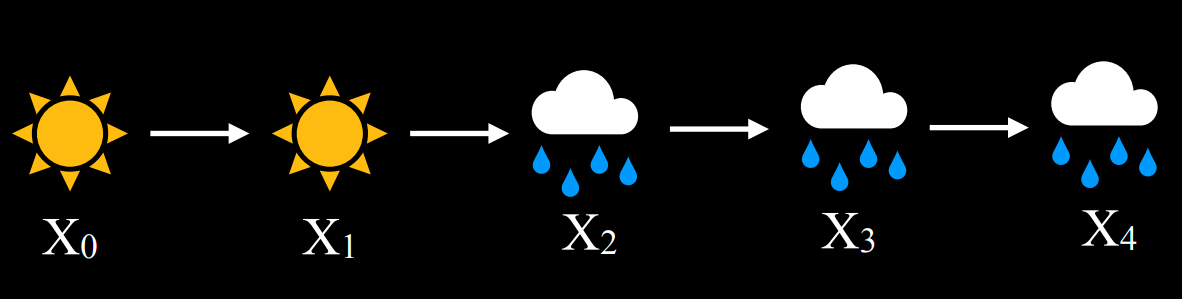

### Demonstração de uma Cadeia de Markov

Usaremos a biblioteca `numpy` para representar a distribuição inicial como um vetor e a matriz de transição como uma matriz, e então aplicaremos a multiplicação matricial.

#### Dados do modelo

O modelo tem dois estados, Sol e Chuva. No dia 0, há 80% de chance de Sol e 20% de chance de Chuva, e a matriz de transição $A$ dá a probabilidade de passar de um estado para o outro.

In [2]:
import numpy as np

# Definição da Distribuição Inicial (W0)
# P(W0) = [P(Sol), P(Chuva)]
P_W0 = np.array([0.8, 0.2])

# Definição da Matriz de Transição (A)
# A = [[P(Sol|Sol), P(Chuva|Sol)],
#      [P(Sol|Chuva), P(Chuva|Chuva)]]

A = np.array([
    [0.6, 0.4],  # Transições a partir de Sol
    [0.1, 0.9]   # Transições a partir de Chuva
])

print(">> Distribuições Iniciais")
print(f"P(W0) = {P_W0}")
print(f"Matriz de Transição T:\n{A}\n")

>> Distribuições Iniciais
P(W0) = [0.8 0.2]
Matriz de Transição T:
[[0.6 0.4]
 [0.1 0.9]]



#### Propagando a distribuição

In [3]:
# Passo 1: Calcular P(W1)
# P(W1) = P(W0) @ A
# @ é o operador de multiplicação matricial

P_W1 = P_W0 @ A

print(">> Previsão do Dia 1 (P(W1)) ---")
print(f"P(W1) = {P_W1}")
print(f"Probabilidade de Sol no Dia 1: (0.6*0.8 + 0.1*0.2 = {P_W1[0]:.1f})")
print(f"Probabilidade de Chuva no Dia 1: (0.4*0.8 + 0.9*0.2 = {P_W1[1]:.1f})")

>> Previsão do Dia 1 (P(W1)) ---
P(W1) = [0.5 0.5]
Probabilidade de Sol no Dia 1: (0.6*0.8 + 0.1*0.2 = 0.5)
Probabilidade de Chuva no Dia 1: (0.4*0.8 + 0.9*0.2 = 0.5)


In [4]:
# Passo 2: Calcular P(W2)
# P(W2) = P(W1) @ A
P_W2 = P_W1 @ A

print(">> Previsão do Dia 2")
print(f"P(W2) = {P_W2}")
print(f"Probabilidade de Sol no Dia 2: {P_W2[0]:.4f}")
print(f"Probabilidade de Chuva no Dia 2: {P_W2[1]:.4f}")

>> Previsão do Dia 2
P(W2) = [0.35 0.65]
Probabilidade de Sol no Dia 2: 0.3500
Probabilidade de Chuva no Dia 2: 0.6500


In [5]:
# Passo 3: Previsão de Longo Prazo (Dia 10)
# A mesma lógica se aplica: P(W_t) = P(W_0) @ T^t
# P(W10) = P(W9) @ T ou P(W0) @ (T @ T @ ... 10 vezes)
A_elevado_a_10 = np.linalg.matrix_power(A, 10)
P_W10 = P_W0 @ A_elevado_a_10

print(">> Previsão de Longo Prazo - Dia 10")
print(f"P(W10) = {P_W10.round(4)}")
print(f"Probabilidade de Sol no Dia 10: {P_W10[0]:.4f}")
print(f"Probabilidade de Chuva no Dia 10: {P_W10[1]:.4f}")

>> Previsão de Longo Prazo - Dia 10
P(W10) = [0.2006 0.7994]
Probabilidade de Sol no Dia 10: 0.2006
Probabilidade de Chuva no Dia 10: 0.7994


<details>
  <summary>Explicação</summary>

Cada passo da previsão aplica a regra da probabilidade total. A probabilidade de Sol amanhã é a soma das probabilidades de chegar a Sol a partir de cada estado possível hoje, ponderadas pela crença atual em cada um deles. Escrita para todos os estados ao mesmo tempo, essa soma é o produto do vetor de crenças pela matriz de transição. Por isso, avançar um dia equivale a multiplicar uma vez pela matriz, e avançar $k$ dias equivale a multiplicar pela matriz elevada a $k$. 

**Esse procedimento às vezes é chamado de algoritmo *mini-forward*.**

A cada multiplicação, a influência da distribuição inicial diminui, porque cada linha da matriz mistura as crenças anteriores com as tendências do próprio sistema. É por isso que, no longo prazo, a cadeia chega a um ponto de equilíbrio que não depende do estado em que começou.

</details>

Uma previsão do tempo para daqui a 1000 dias é confiável? Para responder, calculamos a previsão para horizontes cada vez mais longos, a partir da mesma crença $P(W_0)$ usada até aqui.

In [6]:
# Passo 4: previsões para horizontes cada vez mais longos
horizons = [10, 50, 100, 500, 1000]

print(">> Previsões a partir de P(W0)")
print("  Dia | P(Sol)  | P(Chuva)")
for day in horizons:
    P_Wk = P_W0 @ np.linalg.matrix_power(A, day)
    print(f"{day:>5} | {P_Wk[0]:.4f}  | {P_Wk[1]:.4f}")

>> Previsões a partir de P(W0)
  Dia | P(Sol)  | P(Chuva)
   10 | 0.2006  | 0.7994
   50 | 0.2000  | 0.8000
  100 | 0.2000  | 0.8000
  500 | 0.2000  | 0.8000
 1000 | 0.2000  | 0.8000


O resultado depende da crença inicial? Repetimos o cálculo partindo de um ponto bem diferente, a certeza de que hoje faz Sol.

In [7]:
# Passo 5: as mesmas previsões partindo da certeza de Sol
certain_sun = np.array([1.0, 0.0])

print(">> Previsões a partir da certeza de Sol")
print("  Dia | P(Sol)  | P(Chuva)")
for day in horizons:
    P_Wk = certain_sun @ np.linalg.matrix_power(A, day)
    print(f"{day:>5} | {P_Wk[0]:.4f}  | {P_Wk[1]:.4f}")

>> Previsões a partir da certeza de Sol
  Dia | P(Sol)  | P(Chuva)
   10 | 0.2008  | 0.7992
   50 | 0.2000  | 0.8000
  100 | 0.2000  | 0.8000
  500 | 0.2000  | 0.8000
 1000 | 0.2000  | 0.8000


#### Interpretação

Nos primeiros dias, a dinâmica do sistema logo se sobrepõe à crença inicial. No dia 0, a probabilidade de Sol era de 80%, mas no dia 1 a distribuição já fica uniforme, com 50% de Sol e 50% de Chuva. No dia 2, a Chuva chega a 65%, porque a probabilidade de continuar chovendo (0,9) é maior que a de continuar fazendo Sol (0,6).

Nos horizontes mais longos, a cadeia se aproxima de um equilíbrio. No dia 10, a previsão está em 20,06% de Sol e, do dia 50 em diante, fica exatamente em 20% de Sol e 80% de Chuva. A distância até esse equilíbrio cai pela metade a cada dia e, por volta do dia 14, já some na quarta casa decimal. Daí em diante, multiplicar de novo pela matriz não muda nada, porque a cadeia chegou à distribuição estacionária, que discutiremos a seguir. 

Esse equilíbrio não depende do ponto de partida. Partindo da certeza de Sol, a previsão do dia 10 fica um pouco mais longe dele, já que o início era mais extremo, mas do dia 50 em diante coincide com a obtida a partir de $P(W_0)$. Quanto mais longe a previsão, menos ela usa a informação sobre o estado atual, até virar a média de longo prazo do sistema, que depende apenas da matriz de transição. 

**A cadeia não fica confusa. Ela apenas esquece o ponto de partida.**

Isso responde se uma previsão para daqui a 1000 dias é confiável. Como frequência de longo prazo, sim, pois, se o modelo estiver correto, cerca de 20% dos dias distantes serão de Sol. Como previsão de um **dia específico**, não, pois ela não acerta mais do que a frequência histórica. 

Neste modelo, a informação sobre o presente se esgota em cerca de duas semanas, e prever o dia 50 ou o dia 1000 dá no mesmo. Há ainda um limite fora do modelo. A cadeia supõe a mesma matriz de transição em todos os dias, o que é falso para o clima real num horizonte de quase três anos, marcado por estações e variações de longo prazo. O exemplo vale, portanto, como ilustração do esquecimento, não como modelo do clima.

### Distribuição estacionária

O equilíbrio observado nos Passos 4 e 5 se chama **distribuição estacionária**, uma distribuição que não muda mais de um passo para o outro. Nem toda cadeia chega a ele vinda de qualquer ponto de partida. Isso só é garantido quando a cadeia é **ergódica**, isto é, quando todo estado pode ser alcançado a partir de qualquer outro e não há oscilações periódicas. Esse esquecimento reaparece mais adiante, na previsão do HMM sem novas observações e nos n-gramas, cujo texto perde o rumo depois de algumas palavras.

## Modelo oculto de Markov

Até aqui, supusemos que o estado do sistema era perfeitamente observável. Para prever $P(\text{Sol amanhã})$, precisávamos saber com certeza se hoje fazia sol ou chovia. Na maioria dos sistemas reais não é assim. O estado que interessa, seja o clima verdadeiro, o sentido de uma frase ou a doença de um paciente, costuma ser oculto. Em vez de observá-lo diretamente, temos acesso apenas a evidências causadas por ele, como o guarda-chuva de alguém, a escolha de uma palavra ou o resultado de um exame.

O **Modelo Oculto de Markov (HMM)** foi concebido para essas situações. Ele permite inferir o estado oculto de um sistema a partir de uma sequência de observações ruidosas.

### O que é o HMM?

O HMM acrescenta a uma Cadeia de Markov uma segunda sequência de variáveis. A camada oculta, formada pelos estados $X_t$, representa a situação real do sistema, que não pode ser vista, e segue a mesma dinâmica de uma Cadeia de Markov simples. No nosso exemplo, ela é o clima real, com os estados Sunny e Rainy. A camada observável, formada pelas evidências $E_t$, representa o que de fato conseguimos observar, e a evidência em cada instante depende apenas do estado oculto naquele instante. No exemplo, ela indica se alguém apareceu com guarda-chuva (Umbrella) ou sem ele (NoUmbrella).

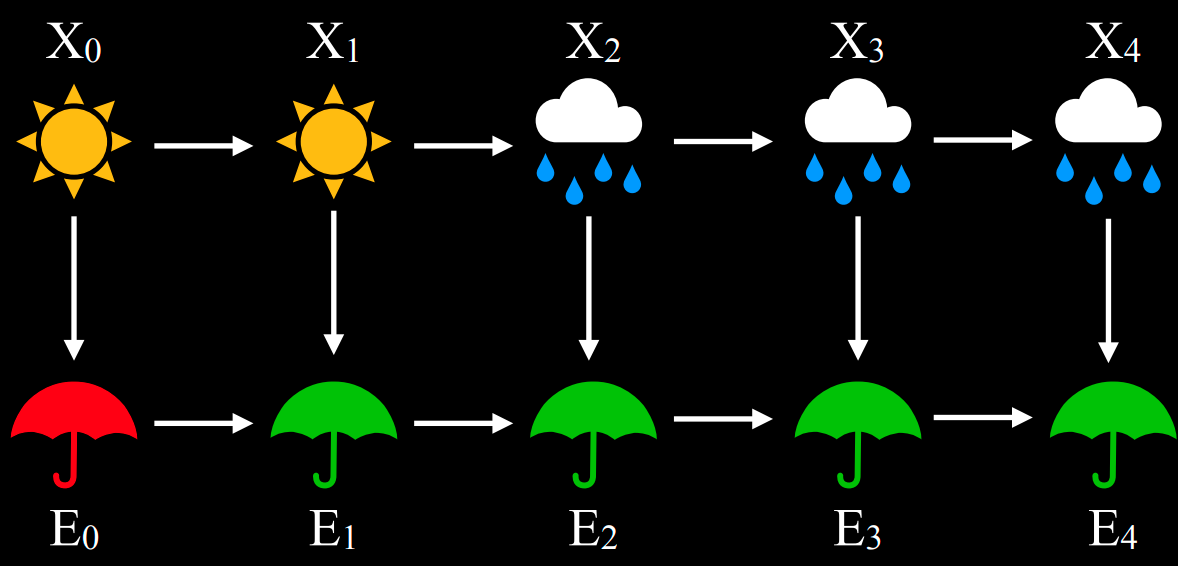

Podemos ver o HMM como uma estrutura que se desdobra no tempo em quadros, um para cada instante $t$. Em cada quadro há um estado oculto $X_t$, que depende apenas do estado anterior $X_{t-1}$, conforme a propriedade de Markov, e uma evidência $E_t$, gerada a partir desse estado. À medida que o tempo avança, o HMM forma uma cadeia dupla de dependências, uma horizontal, entre os estados ocultos, e outra vertical, entre cada estado e a sua observação.

### Componentes de um HMM

Um HMM é definido por três conjuntos de parâmetros, que descrevem como os estados ocultos evoluem e como produzem observações. A **matriz de transição** $A$ dá as probabilidades de mudança entre estados ocultos e responde a perguntas como qual é a probabilidade de chover amanhã se hoje está ensolarado. A **matriz de emissão** $B$ liga cada estado oculto às observações e indica, por exemplo, a probabilidade de alguém usar guarda-chuva quando o clima é chuvoso. Por fim, a **distribuição inicial** $\pi$ dá a probabilidade de cada estado oculto no primeiro instante e define, portanto, o ponto de partida do processo.

### Inferência e aprendizagem de um HMM

Conhecidos os três parâmetros, o HMM descreve como as sequências de estados e de observações são geradas e pode ser usado no sentido inverso, das observações para os estados ocultos. A **avaliação** calcula a probabilidade de uma sequência de observações ter sido gerada pelo modelo, o que permite medir o quanto ele explica os dados (algoritmo *Forward*). A **filtragem** e a **suavização** estimam a crença sobre o estado oculto em cada instante, a primeira com as observações até aquele instante (algoritmo *Forward*) e a segunda com a sequência inteira (algoritmo *Forward-Backward*), enquanto a **previsão** projeta essa crença para instantes futuros. A **decodificação** encontra a sequência de estados ocultos mais provável para as observações (algoritmo de Viterbi).

Quando não são conhecidos $A$, $B$ e $\pi$, a **aprendizagem** os estima a partir de sequências observadas, com o algoritmo de Baum-Welch. Na demonstração a seguir, os parâmetros são definidos manualmente, e por isso trataremos apenas das tarefas de inferência.

### Demonstração do HMM

A seguir, implementaremos o HMM conhecido como mundo do guarda-chuva. O clima real é o estado oculto, que não pode ser visto e observamos apenas as suas evidências, que têm duas opções, `Umbrella` e `NoUmbrella`.

Em relação ao exemplo clássico com dois estados, acrescentamos um terceiro estado oculto, `Foggy` (neblina), um clima intermediário em que as pessoas às vezes levam guarda-chuva e às vezes não. Com ele, uma mesma observação passa a ser compatível com mais de uma explicação, o que torna a inferência mais interessante. Os estados ocultos são, portanto, `Sunny`, `Rainy` e `Foggy`.

Usaremos a biblioteca `hmmlearn` e seguiremos estas etapas:

1. Definir manualmente os parâmetros do HMM, que são a distribuição inicial $\pi$ (por exemplo, 40% de chance de começar com `Sunny`), a matriz de transição $A$, que descreve como o clima evolui de um dia para o outro, e a matriz de emissão $B$, que dá a probabilidade de vermos ou não um guarda-chuva em cada clima.
2. Definir a sequência de observações registrada por um observador que não vê o céu, apenas se as pessoas chegam com guarda-chuva.
3. Calcular a probabilidade da sequência observada segundo o modelo (avaliação).
4. Encontrar, com o algoritmo de Viterbi, a sequência de climas mais provável para essas observações (decodificação).
5. Calcular a crença sobre o clima em cada dia, primeiro com as observações até aquele dia e depois com a sequência inteira (filtragem e suavização).
6. Prever, a partir da crença sobre o último dia, a distribuição do clima no dia seguinte (previsão).

In [8]:
import numpy as np
from hmmlearn import hmm

# Estados ocultos (W_t): representam o clima real, que não é observado diretamente
states = ["Sunny", "Rainy", "Foggy"]

# Observações possíveis (E_t): o que podemos ver no mundo real
# Neste exemplo, 0 = Umbrella (alguém usando guarda-chuva) e 1 = NoUmbrella
obs = ["Umbrella", "NoUmbrella"]

# Distribuição inicial (π): probabilidade de começar em cada estado
pi = np.array([0.4, 0.3, 0.3])

# Matriz de transição (A): P(W_{t+1} | W_t)
# Cada linha indica a probabilidade de passar do estado atual para o próximo
A = np.array([
    [0.65, 0.25, 0.10],  # de Sunny -> [Sunny, Rainy, Foggy]
    [0.20, 0.65, 0.15],  # de Rainy -> [Sunny, Rainy, Foggy]
    [0.25, 0.35, 0.40],  # de Foggy -> [Sunny, Rainy, Foggy]
])

# Matriz de emissão (B): P(E_t | W_t)
# Liga os estados ocultos (clima real) às observações (guarda-chuva ou não)
B = np.array([
    [0.05, 0.95],  # Sunny  -> P(umbrella)=0.05, P(no)=0.95
    [0.90, 0.10],  # Rainy  -> P(umbrella)=0.90, P(no)=0.10
    [0.40, 0.60],  # Foggy  -> P(umbrella)=0.40, P(no)=0.60
])

In [9]:
# CategoricalHMM: HMM para observações discretas, em que cada observação é um símbolo
# init_params="" impede que o modelo sobrescreva os parâmetros definidos manualmente
model = hmm.CategoricalHMM(n_components=len(states), init_params="")

# Atribui manualmente os parâmetros definidos anteriormente
model.startprob_    = pi        # Distribuição inicial (π)
model.transmat_     = A         # Matriz de transição (A)
model.emissionprob_ = B         # Matriz de emissão (B)
model.n_features    = len(obs)  # Número de símbolos observáveis

# Sequência observada
# Umbrella → Umbrella → NoUmbrella → NoUmbrella → NoUmbrella → Umbrella → Umbrella → Umbrella
# Cada observação é o índice do símbolo em `obs` (0 = Umbrella, 1 = NoUmbrella).
# hmmlearn espera um array 2D de formato (T, 1), com uma linha por instante de tempo.
O = np.array([0, 0, 1, 1, 1, 0, 0, 0]).reshape(-1, 1)

In [10]:
O

array([[0],
       [0],
       [1],
       [1],
       [1],
       [0],
       [0],
       [0]])

#### Avaliação

Começamos verificando se o modelo é coerente com o que foi observado. A avaliação calcula a probabilidade $P(e_{1:T})$ que o HMM atribui a essas oito observações. Sozinho, esse número diz pouco, mas ele se torna útil quando comparamos modelos diferentes diante dos mesmos dados, já que o modelo que atribui maior probabilidade às observações é o que melhor as explica. O cálculo é feito pelo algoritmo *Forward*.

In [11]:
# Avaliação (algoritmo Forward): log P(e_1, ..., e_T)
log_likelihood = model.score(O)

print(f"log P(observações) = {log_likelihood:.4f}")
print(f"P(observações)     = {np.exp(log_likelihood):.6f}")

log P(observações) = -5.4209
P(observações)     = 0.004423


#### Decodificação

Aqui queremos reconstruir a história mais provável do clima, isto é, a sequência de estados ocultos que melhor explica todas as observações em conjunto. O algoritmo de Viterbi encontra essa sequência sem precisar testar todas as combinações possíveis de climas.

In [12]:
# Decodificação (Viterbi): melhor sequência de estados ocultos
logp, hidden = model.decode(O, algorithm="viterbi")
viterbi_path = [states[i] for i in hidden]

print("Viterbi path:", viterbi_path)

Viterbi path: ['Rainy', 'Rainy', 'Sunny', 'Sunny', 'Sunny', 'Rainy', 'Rainy', 'Rainy']


#### Filtragem

Queremos saber o que um agente pode concluir sobre o clima de cada dia no momento em que ele acontece, sem conhecer o futuro. A filtragem calcula $P(X_t \mid e_{1:t})$ usando apenas as observações até o dia $t$ e, a cada novo dia, atualiza a crença anterior com a nova evidência (algoritmo *Forward*).

In [13]:
def forward_filter(model, O):
    # Filtragem: P(X_t | e_1, ..., e_t) para cada instante t
    belief = model.startprob_ * model.emissionprob_[:, O[0, 0]]
    beliefs = [belief / belief.sum()]
    for o in O[1:, 0]:
        # Projeta a crença um passo à frente e a atualiza com a nova evidência
        belief = (beliefs[-1] @ model.transmat_) * model.emissionprob_[:, o]
        beliefs.append(belief / belief.sum())
    return np.array(beliefs)

In [14]:
import pandas as pd

filtered = forward_filter(model, O)

# Crença filtrada em cada dia (linhas) para cada estado oculto (colunas)
day_labels = [f"t={t} {obs[o]}" for t, o in enumerate(O[:, 0])]
pd.DataFrame(filtered, columns=states, index=day_labels).round(3)

,Sunny,Rainy,Foggy
t=0 Umbrella,0.049,0.659,0.293
t=1 Umbrella,0.020,0.830,0.150
t=2 NoUmbrella,0.545,0.158,0.297
t=3 NoUmbrella,0.741,0.058,0.200
t=4 NoUmbrella,0.802,0.046,0.152
t=5 Umbrella,0.083,0.744,0.173
t=6 Umbrella,0.021,0.853,0.127
t=7 Umbrella,0.017,0.867,0.115


#### Suavização

Depois que a sequência inteira foi observada, podemos revisar a crença sobre cada dia usando também o que aconteceu depois dele. A suavização calcula $P(X_t \mid e_{1:T})$ e tende a ser mais precisa que a filtragem, porque as **observações posteriores ajudam a confirmar ou a corrigir a estimativa** (algoritmo *Forward-Backward*).

In [15]:
# Suavização (Forward-Backward): P(X_t | e_1, ..., e_T) para cada instante t
smoothed = model.predict_proba(O)

pd.DataFrame(smoothed, columns=states, index=day_labels).round(3)

,Sunny,Rainy,Foggy
t=0 Umbrella,0.027,0.709,0.263
t=1 Umbrella,0.043,0.754,0.203
t=2 NoUmbrella,0.662,0.087,0.251
t=3 NoUmbrella,0.771,0.038,0.191
t=4 NoUmbrella,0.694,0.093,0.213
t=5 Umbrella,0.039,0.828,0.133
t=6 Umbrella,0.010,0.892,0.099
t=7 Umbrella,0.017,0.867,0.115


#### Comparando filtragem e suavização

Reunimos a filtragem, a suavização e o caminho de Viterbi em uma única tabela para identificar os dias em que conhecer o restante da sequência muda a crença sobre o clima.

In [16]:
beliefs_table = pd.DataFrame({
    "observação": [obs[o] for o in O[:, 0]],
    "Viterbi": viterbi_path,
    **{f"filtragem {s}": filtered[:, i] for i, s in enumerate(states)},
    **{f"suavização {s}": smoothed[:, i] for i, s in enumerate(states)},
}).round(3)

beliefs_table

,observação,Viterbi,filtragem Sunny,filtragem Rainy,filtragem Foggy,suavização Sunny,suavização Rainy,suavização Foggy
0,Umbrella,Rainy,0.049,0.659,0.293,0.027,0.709,0.263
1,Umbrella,Rainy,0.020,0.830,0.150,0.043,0.754,0.203
2,NoUmbrella,Sunny,0.545,0.158,0.297,0.662,0.087,0.251
3,NoUmbrella,Sunny,0.741,0.058,0.200,0.771,0.038,0.191
4,NoUmbrella,Sunny,0.802,0.046,0.152,0.694,0.093,0.213
5,Umbrella,Rainy,0.083,0.744,0.173,0.039,0.828,0.133
6,Umbrella,Rainy,0.021,0.853,0.127,0.010,0.892,0.099
7,Umbrella,Rainy,0.017,0.867,0.115,0.017,0.867,0.115


#### Previsão

Por fim, queremos antecipar o clima do dia seguinte, para o qual ainda não há observações. Para isso, projetamos a crença filtrada do último dia um passo à frente usando a matriz de transição. No último dia, a crença filtrada coincide com a suavizada, pois não há observações posteriores, e usá-la deixa claro que a previsão é a continuação da filtragem, disponível em tempo real.

In [17]:
# Previsão: projeta a crença filtrada do último dia um passo à frente
next_day = filtered[-1] @ model.transmat_

# A variavel states contém os nomes dos estados ocultos
print(">> Previsão para o dia seguinte (t = 8)")
for s, p in zip(states, next_day):
    print(f"P({s}) = {p:.3f}")

>> Previsão para o dia seguinte (t = 8)
P(Sunny) = 0.214
P(Rainy) = 0.609
P(Foggy) = 0.178


#### Interpretação

A probabilidade da sequência observada é de aproximadamente 0,0044. O valor parece pequeno, mas qualquer sequência específica de oito dias é pouco provável. A avaliação ganha sentido quando comparamos modelos, já que o modelo que atribui maior probabilidade às mesmas observações é o que melhor as explica.

O algoritmo de Viterbi não atribuiu `Rainy` a todos os dias. O caminho encontrado, `['Rainy', 'Rainy', 'Sunny', 'Sunny', 'Sunny', 'Rainy', 'Rainy', 'Rainy']`, é a trajetória de maior probabilidade conjunta quando todas as observações são consideradas. A transição de `Rainy` para `Sunny` no dia 2 tem um custo, mas ele é compensado pela alta probabilidade de emissão $P(\text{NoUmbrella} \mid \text{Sunny}) = 0.95$, que explica melhor a evidência.

A comparação entre filtragem e suavização mostra o ganho de conhecer o restante da sequência. No dia 2, quando aparece o primeiro `NoUmbrella`, a filtragem atribui 54,5% a `Sunny`, pois ainda não sabe se a mudança vai se confirmar. A suavização, que já considera os dias 3 e 4 sem guarda-chuva, eleva essa crença para 66,2%. No dia 4 ocorre o contrário. A filtragem chega a 80,2% de `Sunny`, e a suavização reduz o valor para 69,4%, porque leva em conta a volta do guarda-chuva no dia 5. No último dia as duas coincidem, com 86,7% de `Rainy`, já que não há observações posteriores.

Por fim, a previsão para o dia seguinte parte dessa crença final e atribui cerca de 60,9% a `Rainy`. O valor é menor que os 86,7% do último dia porque, sem uma nova observação, resta apenas aplicar a matriz de transição, e a linha de `Rainy` (`[0.20, 0.65, 0.15]`) admite que o clima mude.

## Exemplos práticos

Os dois cenários a seguir usam cadeias de Markov visíveis, em que os estados são as próprias palavras e podem ser observados diretamente.

O Modelo Oculto de Markov também pode ser usado na produção de texto quando as palavras dependem de uma estrutura que não aparece diretamente no texto. Os estados ocultos podem representar, por exemplo, as classes gramaticais, o que permite gerar frases com uma estrutura sintática plausível, ou o tópico de cada trecho, o que permite alternar entre assuntos ao longo de um texto mais longo. Em reconhecimento de fala e de escrita à mão, o HMM ajuda ainda a produzir o texto mais provável a partir de sinais ruidosos, que nesse caso são as observações.

### Cenário 01 - Cadeia de Markov de palavras (bigramas)

Até aqui, os estados da cadeia representavam o clima de cada dia. A mesma ideia vale para qualquer sequência em que cada elemento depende dos anteriores e um texto é exatamente isso, uma sequência de palavras em que a próxima depende do que já foi escrito. 

Em Processamento de Linguagem Natural (PLN), uma forma simples de fazer isso é usar **n-gramas**, que são sequências de $n$ elementos consecutivos de um texto, em geral palavras ou caracteres. Na frase "o gato dorme", por exemplo, os unigramas são "o", "gato" e "dorme", os bigramas são "o gato" e "gato dorme", e o único trigrama é a própria frase.

Neste cenário, voltamos a uma Cadeia de Markov observável, em que as próprias palavras são os estados. Um modelo de bigramas supõe que a próxima palavra depende apenas da palavra atual, assim como o clima de amanhã dependia apenas do clima de hoje.

In [18]:
import numpy as np
import pandas as pd
import nltk

from nltk import word_tokenize, bigrams

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

True

#### Definindo um pequeno corpus

O corpus a seguir reúne frases simples em português, criadas para fins didáticos. As frases têm palavras em comum, entre elas "o", "gato", "cachorro" e "com", e por isso o modelo pode recombinar transições aprendidas em frases diferentes e produzir sequências que não estão no corpus. Em uma aplicação real, o corpus seria formado por notícias, livros, mensagens ou outros textos, como faremos no Cenário 02.

In [19]:
corpus = [
    "o gato dorme no sofá",
    "o cachorro dorme na varanda",
    "o gato come peixe",
    "o cachorro come ração",
    "o cachorro late para o carteiro",
    "o menino brinca com o gato",
    "a menina brinca com o cachorro",
]

In [20]:
tokenized_sentences = []

# O <s> e </s> são tokens especiais que indicam o início e o fim de uma sentença
for sentence in corpus:
    tokens = word_tokenize(sentence.lower(), language="portuguese")
    tokens = ["<s>"] + tokens + ["</s>"]
    tokenized_sentences.append(tokens)

tokenized_sentences

[['<s>', 'o', 'gato', 'dorme', 'no', 'sofá', '</s>'],
 ['<s>', 'o', 'cachorro', 'dorme', 'na', 'varanda', '</s>'],
 ['<s>', 'o', 'gato', 'come', 'peixe', '</s>'],
 ['<s>', 'o', 'cachorro', 'come', 'ração', '</s>'],
 ['<s>', 'o', 'cachorro', 'late', 'para', 'o', 'carteiro', '</s>'],
 ['<s>', 'o', 'menino', 'brinca', 'com', 'o', 'gato', '</s>'],
 ['<s>', 'a', 'menina', 'brinca', 'com', 'o', 'cachorro', '</s>']]

#### Extraindo bigramas

Com as frases divididas em tokens, podemos extrair os bigramas. Cada bigrama representa a transição de uma palavra para a palavra seguinte.

In [21]:
all_bigrams = []

for sentence in tokenized_sentences:
    all_bigrams.extend(list(bigrams(sentence)))

all_bigrams

[('<s>', 'o'),
 ('o', 'gato'),
 ('gato', 'dorme'),
 ('dorme', 'no'),
 ('no', 'sofá'),
 ('sofá', '</s>'),
 ('<s>', 'o'),
 ('o', 'cachorro'),
 ('cachorro', 'dorme'),
 ('dorme', 'na'),
 ('na', 'varanda'),
 ('varanda', '</s>'),
 ('<s>', 'o'),
 ('o', 'gato'),
 ('gato', 'come'),
 ('come', 'peixe'),
 ('peixe', '</s>'),
 ('<s>', 'o'),
 ('o', 'cachorro'),
 ('cachorro', 'come'),
 ('come', 'ração'),
 ('ração', '</s>'),
 ('<s>', 'o'),
 ('o', 'cachorro'),
 ('cachorro', 'late'),
 ('late', 'para'),
 ('para', 'o'),
 ('o', 'carteiro'),
 ('carteiro', '</s>'),
 ('<s>', 'o'),
 ('o', 'menino'),
 ('menino', 'brinca'),
 ('brinca', 'com'),
 ('com', 'o'),
 ('o', 'gato'),
 ('gato', '</s>'),
 ('<s>', 'a'),
 ('a', 'menina'),
 ('menina', 'brinca'),
 ('brinca', 'com'),
 ('com', 'o'),
 ('o', 'cachorro'),
 ('cachorro', '</s>')]

#### Construindo e inspecionando a matriz de contagens

Para construir a matriz de contagens, precisamos de uma representação numérica das palavras. Primeiro, reunimos todos os tokens distintos do corpus em um vocabulário e associamos a cada palavra um índice, que indica a sua posição nas linhas e colunas da matriz. Também guardamos o caminho inverso, do índice para a palavra, para poder ler os resultados.

A matriz de contagens é quadrada. Cada linha corresponde à palavra atual e cada coluna à palavra seguinte. Para cada bigrama do corpus, somamos 1 à célula correspondente, de modo que a matriz registra quantas vezes cada transição ocorreu. Como a maior parte das células é zero, listamos em seguida apenas as transições observadas, o que facilita a leitura.

In [22]:
vocabulary = sorted(set(token for sentence in tokenized_sentences for token in sentence))

word_to_index = {word: i for i, word in enumerate(vocabulary)}
index_to_word = {i: word for word, i in word_to_index.items()}

In [23]:
n_words = len(vocabulary)
count_matrix = np.zeros((n_words, n_words), dtype=int)

for current_word, next_word in all_bigrams:
    i = word_to_index[current_word]
    j = word_to_index[next_word]
    count_matrix[i, j] += 1

pd.DataFrame(count_matrix, index=vocabulary, columns=vocabulary)

,</s>,<s>,a,brinca,cachorro,carteiro,com,come,dorme,gato,...,menina,menino,na,no,o,para,peixe,ração,sofá,varanda
</s>,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
<s>,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,6,0,0,0,0,0
a,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
brinca,0,0,0,0,0,0,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
cachorro,1,0,0,0,0,0,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
carteiro,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
com,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,0,0,0,0,0
come,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0
dorme,0,0,0,0,0,0,0,0,0,0,...,0,0,1,1,0,0,0,0,0,0
gato,1,0,0,0,0,0,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0


In [24]:
print(">> Transições observadas:\n")

for i, current_word in enumerate(vocabulary):
    for j, next_word in enumerate(vocabulary):
        if count_matrix[i, j] > 0:
            print(f"{current_word} -> {next_word}: {count_matrix[i, j]}")

>> Transições observadas:

<s> -> a: 1
<s> -> o: 6
a -> menina: 1
brinca -> com: 2
cachorro -> </s>: 1
cachorro -> come: 1
cachorro -> dorme: 1
cachorro -> late: 1
carteiro -> </s>: 1
com -> o: 2
come -> peixe: 1
come -> ração: 1
dorme -> na: 1
dorme -> no: 1
gato -> </s>: 1
gato -> come: 1
gato -> dorme: 1
late -> para: 1
menina -> brinca: 1
menino -> brinca: 1
na -> varanda: 1
no -> sofá: 1
o -> cachorro: 4
o -> carteiro: 1
o -> gato: 3
o -> menino: 1
para -> o: 1
peixe -> </s>: 1
ração -> </s>: 1
sofá -> </s>: 1
varanda -> </s>: 1


#### Convertendo contagens em probabilidades de transição

Para transformar a matriz de contagens em uma **matriz de transição**, dividimos cada linha pela sua soma. Cada linha passa então a representar uma distribuição de probabilidade

$$
P(w_{t+1} \mid w_t)
$$

que dá, para a palavra atual $w_t$, a probabilidade de cada palavra seguinte.

In [25]:
row_sums = count_matrix.sum(axis=1, keepdims=True)

transition_matrix = np.divide(
    count_matrix,
    row_sums,
    out=np.zeros_like(count_matrix, dtype=float),
    where=row_sums != 0
)

pd.DataFrame(transition_matrix, index=vocabulary, columns=vocabulary).round(2)

,</s>,<s>,a,brinca,cachorro,carteiro,com,come,dorme,gato,...,menina,menino,na,no,o,para,peixe,ração,sofá,varanda
</s>,0.00,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.00,...,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0
<s>,0.00,0.0,0.14,0.0,0.00,0.00,0.0,0.00,0.00,0.00,...,0.0,0.00,0.0,0.0,0.86,0.0,0.0,0.0,0.0,0.0
a,0.00,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.00,...,1.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0
brinca,0.00,0.0,0.00,0.0,0.00,0.00,1.0,0.00,0.00,0.00,...,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0
cachorro,0.25,0.0,0.00,0.0,0.00,0.00,0.0,0.25,0.25,0.00,...,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0
carteiro,1.00,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.00,...,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0
com,0.00,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.00,...,0.0,0.00,0.0,0.0,1.00,0.0,0.0,0.0,0.0,0.0
come,0.00,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.00,...,0.0,0.00,0.0,0.0,0.00,0.0,0.5,0.5,0.0,0.0
dorme,0.00,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.00,...,0.0,0.00,0.5,0.5,0.00,0.0,0.0,0.0,0.0,0.0
gato,0.33,0.0,0.00,0.0,0.00,0.00,0.0,0.33,0.33,0.00,...,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0


In [26]:
print(">> Matriz de transição interpretada:\n")
print("Cada linha representa a palavra atual.")
print("Cada coluna representa uma possível próxima palavra.")
print("Os valores indicam P(próxima palavra | palavra atual).\n")

for i, current_word in enumerate(vocabulary):
    probabilities = transition_matrix[i]

    # Ignora palavras sem transições observadas
    if probabilities.sum() == 0:
        print(f"'{current_word}' não possui próximas palavras observadas no corpus.")
        continue

    print(f"\nSe a palavra atual é '{current_word}', então:")

    for j, next_word in enumerate(vocabulary):
        probability = probabilities[j]

        if probability > 0:
            print(f"  P({next_word} | {current_word}) = {probability:.3f}")

>> Matriz de transição interpretada:

Cada linha representa a palavra atual.
Cada coluna representa uma possível próxima palavra.
Os valores indicam P(próxima palavra | palavra atual).

'</s>' não possui próximas palavras observadas no corpus.

Se a palavra atual é '<s>', então:
  P(a | <s>) = 0.143
  P(o | <s>) = 0.857

Se a palavra atual é 'a', então:
  P(menina | a) = 1.000

Se a palavra atual é 'brinca', então:
  P(com | brinca) = 1.000

Se a palavra atual é 'cachorro', então:
  P(</s> | cachorro) = 0.250
  P(come | cachorro) = 0.250
  P(dorme | cachorro) = 0.250
  P(late | cachorro) = 0.250

Se a palavra atual é 'carteiro', então:
  P(</s> | carteiro) = 1.000

Se a palavra atual é 'com', então:
  P(o | com) = 1.000

Se a palavra atual é 'come', então:
  P(peixe | come) = 0.500
  P(ração | come) = 0.500

Se a palavra atual é 'dorme', então:
  P(na | dorme) = 0.500
  P(no | dorme) = 0.500

Se a palavra atual é 'gato', então:
  P(</s> | gato) = 0.333
  P(come | gato) = 0.333
  P(dorm

In [27]:
def show_next_words(word, top_k=5):
    """
    Mostra as palavras mais prováveis de aparecer depois de uma palavra específica.
    """
    if word not in word_to_index:
        print(f"A palavra '{word}' não está no vocabulário.")
        return

    i = word_to_index[word]
    probabilities = transition_matrix[i]

    sorted_indices = np.argsort(probabilities)[::-1]

    print(f"Próximas palavras mais prováveis depois de '{word}':\n")

    for idx in sorted_indices[:top_k]:
        if probabilities[idx] > 0:
            print(f"{index_to_word[idx]}: {probabilities[idx]:.3f}")

In [28]:
show_next_words("o")

Próximas palavras mais prováveis depois de 'o':

cachorro: 0.444
gato: 0.333
carteiro: 0.111
menino: 0.111


In [29]:
show_next_words("cachorro")

Próximas palavras mais prováveis depois de 'cachorro':

dorme: 0.250
come: 0.250
</s>: 0.250
late: 0.250


Como o corpus é pequeno, podemos visualizar a cadeia inteira na figura abaixo. Cada nó é uma palavra, cada seta é uma transição observada no corpus e o número sobre ela é a probabilidade de transição. Gerar uma frase equivale a percorrer esse grafo de `<s>` até `</s>`, sorteando em cada palavra uma das setas de saída.

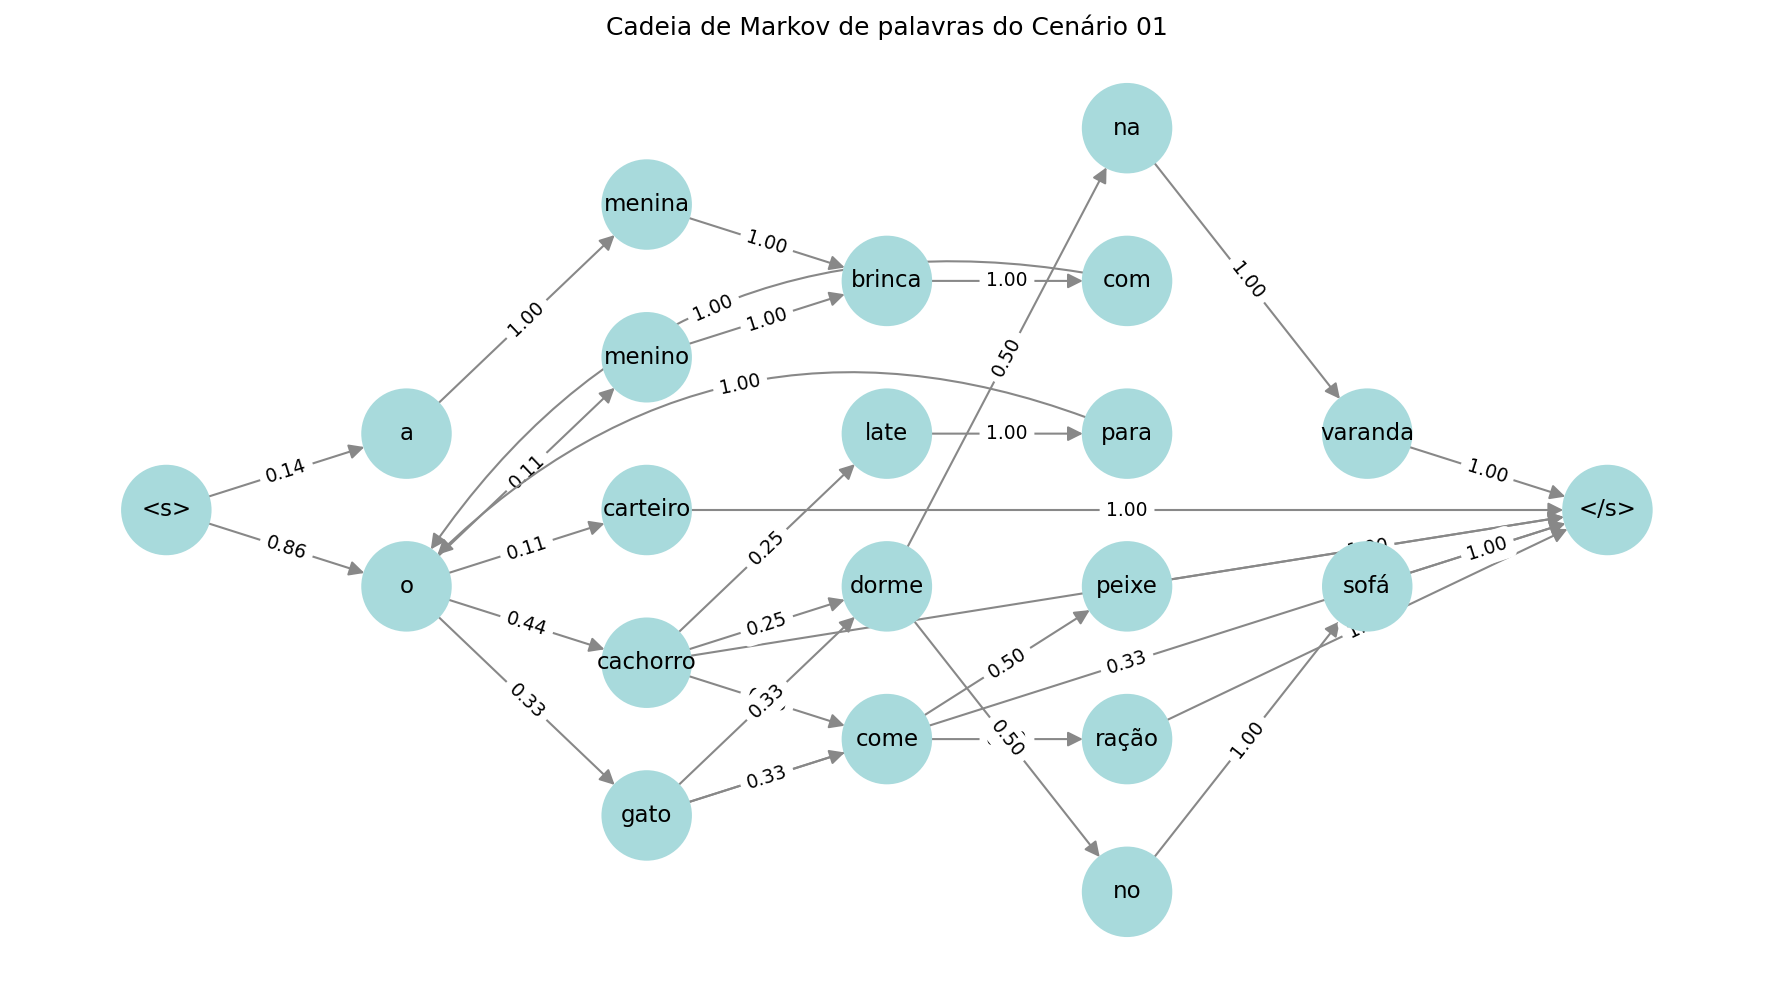

As palavras estão organizadas em colunas pela distância ao início da frase. As setas curvas que saem de "com" e de "para" e voltam para "o" formam ciclos. É por eles que o modelo consegue produzir frases mais longas que as do corpus e combinar o início de uma frase com o final de outra, como veremos a seguir.

In [30]:
def generate_markov_sentence(
    transition_matrix,
    initial_word="<s>",
    max_words=10,
    seed=42
):
    """
    Gera uma frase usando uma Cadeia de Markov baseada na matriz de transição.

    A geração começa no token inicial `<s>` e continua até encontrar o token
    de fim `</s>` ou atingir o número máximo de palavras.
    """
    rng = np.random.default_rng(seed)

    current_word = initial_word
    sentence = []

    for _ in range(max_words):
        i = word_to_index[current_word]
        probabilities = transition_matrix[i]

        if probabilities.sum() == 0:
            break

        next_index = rng.choice(len(vocabulary), p=probabilities)
        next_word = index_to_word[next_index]

        if next_word == "</s>":
            break

        sentence.append(next_word)
        current_word = next_word

    return " ".join(sentence)

Vamos gerar algumas frases com sementes aleatórias diferentes. Como o modelo sorteia a próxima palavra de acordo com as probabilidades de transição, sementes diferentes podem produzir frases diferentes.

In [31]:
for seed in range(5):
    print(f"Frase {seed + 1}: {generate_markov_sentence(transition_matrix, seed=seed)}")

Frase 1: o cachorro
Frase 2: o menino brinca com o cachorro late para o cachorro
Frase 3: o cachorro late para o gato
Frase 4: a menina brinca com o cachorro come peixe
Frase 5: o carteiro


Também podemos escolher a palavra pela qual a geração começa. Em vez de partir de `<s>`, a cadeia sorteia a próxima palavra a partir da linha da palavra escolhida na matriz de transição. Como a matriz guarda apenas as transições para a palavra seguinte, a geração avança a partir dessa palavra, mas não produz o que viria antes dela. A palavra escolhida também precisa estar no vocabulário, pois só assim existe uma linha da matriz para ela.

In [32]:
# A função não inclui a palavra inicial na frase devolvida,
# por isso a acrescentamos na impressão
word = "menino"
for seed in range(3):
    continuation = generate_markov_sentence(transition_matrix, initial_word=word, seed=seed)
    print(f"{word} {continuation}")

menino brinca com o cachorro late para o gato come ração
menino brinca com o menino brinca com o cachorro dorme na
menino brinca com o cachorro dorme no sofá


Finalmente, como as frases do corpus têm palavras em comum, o modelo pode combinar trechos de frases diferentes. Vejamos quais das frases geradas são inéditas, isto é, não aparecem no corpus.

In [33]:
corpus_sentences = set(corpus)

for seed in range(10):
    sentence = generate_markov_sentence(transition_matrix, seed=seed)
    status = "copiada do corpus" if sentence in corpus_sentences else "INÉDITA"
    print(f"{sentence:<60} [{status}]")

o cachorro                                                   [INÉDITA]
o menino brinca com o cachorro late para o cachorro          [INÉDITA]
o cachorro late para o gato                                  [INÉDITA]
a menina brinca com o cachorro come peixe                    [INÉDITA]
o carteiro                                                   [INÉDITA]
o gato come peixe                                            [copiada do corpus]
o cachorro come peixe                                        [INÉDITA]
o menino brinca com o gato                                   [copiada do corpus]
o menino brinca com o cachorro come peixe                    [INÉDITA]
o cachorro dorme no sofá                                     [INÉDITA]


Das dez frases geradas, oito não estão no corpus. Algumas são inéditas e plausíveis, como "o cachorro dorme no sofá" e "o cachorro come peixe", que unem o início de uma frase ao final de outra. Outras mostram a principal limitação do modelo, como "o menino brinca com o cachorro late para o cachorro". Cada transição dessa frase aparece no corpus, mas o modelo só considera a palavra atual. Ao chegar a "cachorro", ele já não sabe que essa palavra era o objeto de "brinca com" e passa a tratá-la como sujeito de uma nova ação. Frases curtas como "o cachorro" e "o carteiro" têm a mesma origem, pois em algum ponto do corpus essas palavras encerram uma frase. O modelo produz frases novas porque não guarda o passado, e é essa mesma falta de memória que torna algumas delas incoerentes.

### Cenário 02 - Gerando texto a partir dos romances de Machado de Assis

O corpus do Cenário 01 é pequeno demais para mostrar as limitações dos modelos de Markov. Neste cenário, treinamos modelos de linguagem com um corpus real, os romances de Machado de Assis disponíveis no NLTK. A obra de Machado costuma ser dividida em duas fases. Os primeiros romances, de *Ressurreição* a *Iaiá Garcia*, pertencem à fase romântica, e com *Memórias Póstumas de Brás Cubas* começa a fase realista, marcada pela ironia, pelas digressões e pelas conversas do narrador com o leitor. Para que o modelo imite um estilo coerente, usamos apenas os cinco romances da fase realista, que somam cerca de 300 mil palavras. A escolha tem um custo, pois menos texto significa menos exemplos de cada sequência de palavras, como veremos ao medir a esparsidade. A pergunta que orienta o cenário é quantas palavras anteriores o modelo deve considerar para prever a próxima.

Um modelo de **n-gramas** prevê a próxima palavra a partir das $n-1$ palavras anteriores:

$$P(w_t \mid w_{t-n+1}, \ldots, w_{t-1})$$

Com $n=2$, temos a cadeia de bigramas do Cenário 01. Com $n=3$, o estado passa a ser o par formado pelas duas últimas palavras, e assim por diante. Um modelo de ordem maior continua sendo uma Cadeia de Markov, mas com um espaço de estados muito maior, já que cada combinação de $n-1$ palavras é um estado. O caso $n=1$, dos unigramas, ignora o contexto e sorteia cada palavra apenas pela sua frequência no corpus.

<details>
  <summary>Quem foi Machado de Assis?</summary>

Joaquim Maria Machado de Assis (1839–1908) é amplamente considerado o maior escritor da literatura brasileira. Nasceu no Morro do Livramento, no Rio de Janeiro, e, pelo lado paterno, descendia de pardos forros — isto é, de africanos alforriados. Teve acesso limitado à educação formal e formou-se sobretudo de maneira autodidata, iniciando a vida profissional como aprendiz de tipógrafo. Tornou-se jornalista, cronista, contista, poeta, dramaturgo e romancista. Em 1897, participou da fundação da Academia Brasileira de Letras, da qual foi o primeiro presidente.

Seus romances da maturidade, como Memórias Póstumas de Brás Cubas, Quincas Borba e Dom Casmurro, renovaram a prosa em língua portuguesa. Machado combina ironia, humor e uma observação aguda da sociedade carioca do século XIX, e experimenta a própria forma do romance: em Brás Cubas, um defunto narra a própria vida; em Dom Casmurro, o narrador pouco confiável alimenta até hoje o debate sobre a possível traição de Capitu.

Sua obra ganhou reconhecimento internacional crescente. A ensaísta norte-americana **Susan Sontag** chamou Machado de Assis de “o maior autor já produzido na América Latina” em seu ensaio [*Afterlives: The Case of Machado de Assis*](https://www.newyorker.com/magazine/1990/05/07/afterlives-the-case-of-machado-de-assis), publicado na *The New Yorker* em 1990. O crítico **Harold Bloom** incluiu Machado entre os cem gênios da literatura em [*Genius: A Mosaic of One Hundred Exemplary Creative Minds*](https://new.scielo.br/j/mael/a/tmyPxQZdNKdwwrhQvzfKJRr/?lang=pt) (2003) e o chamou de “o maior artista literário negro até agora”. Em 2020, a nova tradução de Memórias Póstumas de Brás Cubas para o inglês, publicada pela Penguin Classics, esgotou em 24 horas nas principais livrarias on-line dos Estados Unidos.

Como Machado morreu há mais de um século, sua obra está em domínio público, o que permite que os romances usados neste cenário sejam distribuídos livremente em corpora como o do NLTK.


**Para saber mais**

* [Biografia de Machado de Assis na Academia Brasileira de Letras](https://www.academia.org.br/academicos/machado-de-assis/biografia)
* [Cronologia da vida de Machado de Assis (Agência Senado)](https://www12.senado.leg.br/noticias/materias/2008/09/26/cronologia-da-vida-de-machado-de-assis)
* [Machado, Brás Cubas e o mistério da vida (Brazil Journal)](https://braziljournal.com/machado-bras-cubas-e-o-misterio-da-vida), sobre o sucesso da tradução da Penguin Classics
* Vídeo: [Letras & Memória: Machado de Assis (TV Brasil)](https://www.youtube.com/watch?v=soy_IqFsgUI)
* Vídeo: [Alcides Villaça, professor da USP, fala sobre Machado de Assis (TV Brasil)](https://www.youtube.com/watch?v=goSgM69MEcQ)
* Vídeo: [Machado de Assis na BBM: primeiras edições e raridades (Biblioteca Brasiliana Guita e José Mindlin, USP)](https://www.youtube.com/watch?v=GJyu3ClhOD4)
* Documentário: [Machado 21: Comemorando o Centenário (Vimeo)](https://vimeo.com/506147884)

</details>

In [34]:
import re
from collections import Counter, defaultdict

from nltk import sent_tokenize
from nltk.corpus import machado

nltk.download("machado", quiet=True)

True

#### Preparando o corpus

In [35]:
# Romances da fase realista, usados no treino
REALIST_NOVELS = [
    "romance/marm05.txt",  # Memórias Póstumas de Brás Cubas (1880)
    "romance/marm07.txt",  # Quincas Borba (1891)
    "romance/marm08.txt",  # Dom Casmurro (1899)
    "romance/marm09.txt",  # Esaú e Jacó (1904)
    "romance/marm10.txt",  # Memorial de Aires (1908)
]

for fileid in machado.fileids(categories="romance"):
    title = machado.raw(fileid).splitlines()[0]
    status = "treino" if fileid in REALIST_NOVELS else "fora do treino"
    print(f"{fileid} -> {title}  [{status}]")

romance/marm01.txt -> ROMANCE, Ressurreição,1872  [fora do treino]
romance/marm02.txt -> ROMANCE, A Mão e a Luva,1874  [fora do treino]
romance/marm03.txt -> ROMANCE, Helena,1876  [fora do treino]
romance/marm04.txt -> ROMANCE, Iaiá Garcia,1878  [fora do treino]
romance/marm05.txt -> Romance, Memórias Póstumas de Brás Cubas, 1880  [treino]
romance/marm06.txt -> ROMANCE, Casa Velha,1885  [fora do treino]
romance/marm07.txt -> ROMANCE, Quincas Borba,1891  [treino]
romance/marm08.txt -> Romance, Dom Casmurro, 1899  [treino]
romance/marm09.txt -> ROMANCE, Esaú e Jacó,1904  [treino]
romance/marm10.txt -> ROMANCE, Memorial de Aires,1908  [treino]


Cada arquivo começa com um cabeçalho editorial, com título, fonte e data de publicação, que não faz parte do texto literário e é removido. Em seguida, dividimos o texto em frases e as frases em palavras, mantendo apenas palavras e sinais de pontuação. Frases muito curtas ou muito longas são descartadas para simplificar a análise.

Essa etapa de **preparação dos dados** exige cuidado, porque decisões que parecem pequenas mudam o que o modelo aprende. Os títulos de capítulo, como "CAPÍTULO II / O EMPLASTO", e as datas que abrem as entradas do *Memorial de Aires* também não fazem parte da narrativa e, se fossem mantidos, ficariam colados à primeira frase de cada capítulo. Um filtro que aceite apenas letras e números descartaria as palavras com hífen, muito comuns em Machado, como "levantou-se" e "disse-lhe", e frases como "Levantou-se, deu alguns passos" passariam a começar por uma vírgula. A célula a seguir mostra o efeito desse filtro em uma frase de exemplo.

In [36]:
example = "Levantou-se, deu alguns passos, encostou-se ao piano."
tokens = word_tokenize(example, language="portuguese")

only_letters = [t for t in tokens if re.fullmatch(r"\w+|[.,;:!?]", t)]
with_hyphen = [t for t in tokens if re.fullmatch(r"\w+(?:-\w+)*|[.,;:!?]", t)]

print("Tokens:               ", tokens)
print("Só letras e números:  ", only_letters)
print("Aceitando o hífen:    ", with_hyphen)

Tokens:                ['Levantou-se', ',', 'deu', 'alguns', 'passos', ',', 'encostou-se', 'ao', 'piano', '.']
Só letras e números:   [',', 'deu', 'alguns', 'passos', ',', 'ao', 'piano', '.']
Aceitando o hífen:     ['Levantou-se', ',', 'deu', 'alguns', 'passos', ',', 'encostou-se', 'ao', 'piano', '.']


A função abaixo reúne essas decisões. Ela remove os títulos de capítulo e as datas, aceita palavras com hífen e trata o travessão que abre as falas dos diálogos como um token próprio, preservando o ritmo da prosa machadiana. Também mantém as letras maiúsculas, o que deixa legíveis nomes como Capitu e Rubião, com o custo de transformar "Não" e "não" em estados diferentes. Por fim, remove a pontuação que ainda sobrar no início de uma frase, o que acontece quando o divisor de frases corta o texto depois de abreviações como "etc." ou "Excia.".

In [37]:
TOKEN_PATTERN = re.compile(r"\w+(?:-\w+)*|[.,;:!?]|—")
DATE_PATTERN = re.compile(r"(\d{4}\s*)?(\d{1,2}\s+de\s+\w+)?\s*\.?", re.IGNORECASE)

def remove_headings(raw):
    # Remove títulos de capítulo e datas de diário, que não fazem parte da narrativa
    kept, after_chapter = [], False
    for paragraph in re.split(r"\n\s*\n", raw):
        text = " ".join(paragraph.split())
        is_chapter = bool(re.match(r"CAP[IÍ]TULO|Cap[ií]tulo\b", text))
        # Em alguns romances, o título vem em um parágrafo próprio, todo em maiúsculas
        is_title = after_chapter and text.isupper()
        is_date = bool(text) and bool(DATE_PATTERN.fullmatch(text))
        after_chapter = is_chapter
        if not (is_chapter or is_title or is_date):
            kept.append(paragraph)
    return "\n\n".join(kept)

def load_machado_sentences(fileids, min_len=4, max_len=40):
    # Lê os romances indicados e devolve uma lista de frases tokenizadas
    sentences = []
    for fileid in fileids:
        raw = machado.raw(fileid)

        # Remove o cabeçalho editorial, que termina em "Publicado originalmente ..."
        header = re.search(r"Publicado\s+originalmente[^\n]*(\n[^\n]+)*\n\s*\n", raw)
        if header:
            raw = raw[header.end():]
        raw = remove_headings(raw)
        # Os travessões dos diálogos aparecem no arquivo como "--" ou como o caractere \x97
        raw = raw.replace("\x97", " — ").replace("--", " — ")
        raw = re.sub(r"\s+", " ", raw)

        for sentence in sent_tokenize(raw, language="portuguese"):
            tokens = word_tokenize(sentence, language="portuguese")
            # Mantém palavras (inclusive com hífen), pontuação simples e o travessão
            tokens = [t for t in tokens if TOKEN_PATTERN.fullmatch(t)]
            # Remove a pontuação que sobra no início de frases cortadas após abreviações
            while tokens and re.fullmatch(r"[.,;:!?]", tokens[0]):
                tokens = tokens[1:]
            if min_len <= len(tokens) <= max_len:
                sentences.append(tokens)
    return sentences

In [38]:
machado_sentences = load_machado_sentences(REALIST_NOVELS)

print(f"Frases:   {len(machado_sentences)}")
print(f"Palavras: {sum(len(s) for s in machado_sentences)}")
print("Exemplo:", machado_sentences[100])

Frases:   18248
Palavras: 307621
Exemplo: ['Corrido', 'o', 'tempo', 'e', 'cessado', 'o', 'espasmo', ',', 'então', 'sim', ',', 'então', 'talvez', 'se', 'pode', 'gozar', 'deveras', ',', 'porque', 'entre', 'uma', 'e', 'outra', 'dessas', 'duas', 'ilusões', ',', 'melhor', 'é', 'a', 'que', 'se', 'gosta', 'sem', 'doer', '.']


#### Separando treino e teste

Para avaliar se o modelo generaliza, reservamos 10% das frases, escolhidas ao acaso, como conjunto de teste. O modelo não as vê durante o treinamento, e elas servirão para medir o quanto ele se surpreende com um texto novo do mesmo autor.

In [39]:
rng = np.random.default_rng(42)
order = rng.permutation(len(machado_sentences))
cut = int(0.9 * len(machado_sentences))

train_sentences = [machado_sentences[i] for i in order[:cut]]
test_sentences = [machado_sentences[i] for i in order[cut:]]

machado_vocabulary = {w for s in train_sentences for w in s} | {"</s>"}

print(f"Treino: {len(train_sentences)} frases | Teste: {len(test_sentences)} frases")
print(f"Vocabulário: {len(machado_vocabulary)} palavras")

Treino: 16423 frases | Teste: 1825 frases
Vocabulário: 22146 palavras


#### Treinando modelos de n-gramas

Com mais de 20 mil palavras no vocabulário, uma matriz de transição completa para bigramas teria centenas de milhões de células, quase todas iguais a zero e para ordens maiores o tamanho seria ainda maior. 

Por isso, em vez de uma matriz, guardamos para cada contexto observado apenas a contagem das palavras que vieram depois dele. O modelo é o mesmo do Cenário 01, o que muda é a forma de armazená-lo. Como antes, marcadores de início e de fim delimitam cada frase. O marcador de início é repetido $n-1$ vezes, para que as primeiras palavras também tenham um contexto completo.

A primeira função acrescenta à frase $n-1$ marcadores de início e um marcador de fim. Assim, as primeiras palavras também têm um contexto completo, e o modelo aprende onde as frases terminam.

In [40]:
def pad(sentence, n):
    # Acrescenta n-1 marcadores de início e um marcador de fim à frase
    return ["<s>"] * (n - 1) + sentence + ["</s>"]

A segunda função percorre cada frase com uma janela de $n-1$ palavras e conta qual palavra veio logo depois de cada janela. O resultado é, para cada contexto, a contagem das palavras que o seguiram.

In [41]:
def train_ngram_model(sentences, n):
    # Conta, para cada contexto de n-1 palavras, quantas vezes cada palavra veio em seguida
    model = defaultdict(Counter)
    for sentence in sentences:
        tokens = pad(sentence, n)
        for i in range(n - 1, len(tokens)):
            context = tuple(tokens[i - n + 1:i])
            model[context][tokens[i]] += 1
    return model

Com essas duas funções, treinamos os modelos de ordem 1 a 4 com as frases de treino dos romances de Machado de Assis.

In [42]:
models = {n: train_ngram_model(train_sentences, n) for n in [1, 2, 3, 4]}

for n, ngram_model in models.items():
    print(f"n = {n}: {len(ngram_model):>7} contextos (estados) distintos")

n = 1:       1 contextos (estados) distintos
n = 2:   22146 contextos (estados) distintos
n = 3:  119428 contextos (estados) distintos
n = 4:  211059 contextos (estados) distintos


Chamamos de **contexto** as $n-1$ palavras que o modelo observa antes de prever a próxima. Na expressão "olhos de ressaca", com que Machado descreve Capitu em *Dom Casmurro*, o modelo de bigramas prevê "de" olhando apenas para "olhos", e o modelo de trigramas prevê "ressaca" olhando para o par "olhos de". Cada contexto corresponde a uma linha da matriz de transição, que guarda a probabilidade de cada palavra seguinte. Vejamos as continuações mais prováveis de "olhos" no modelo de bigramas e de "olhos de" no modelo de trigramas.

Guardar os contextos dessa forma traz uma grande vantagem computacional. Uma matriz de transição completa para bigramas teria uma linha e uma coluna para cada uma das cerca de 22 mil palavras do vocabulário, perto de 490 milhões de células, mas apenas cerca de 120 mil pares de palavras aparecem de fato no corpus, cerca de 0,02% do total. Para trigramas, as linhas passariam a ser todos os pares possíveis de palavras, e a matriz chegaria a cerca de 11 trilhões de células, das quais o modelo guarda apenas cerca de 218 mil. Como o dicionário armazena somente as transições observadas, a memória necessária cresce com o tamanho do corpus, e não com o número de combinações possíveis de palavras, o que torna viável treinar modelos de ordem maior.

In [43]:
def show_next_words_ngram(ngram_model, context, top_k=5):
    # Mostra as continuações mais prováveis de um contexto
    counts = ngram_model.get(tuple(context), Counter())
    total = sum(counts.values())
    print(f"Contexto {tuple(context)}: {total} ocorrências")
    for word, count in counts.most_common(top_k):
        print(f"  P({word} | contexto) = {count / total:.3f}")
    print()

In [44]:
show_next_words_ngram(models[2], ["olhos"])
show_next_words_ngram(models[3], ["olhos", "de"])

Contexto ('olhos',): 487 ocorrências
  P(, | contexto) = 0.166
  P(. | contexto) = 0.092
  P(de | contexto) = 0.088
  P(no | contexto) = 0.045
  P(e | contexto) = 0.035

Contexto ('olhos', 'de'): 43 ocorrências
  P(ressaca | contexto) = 0.140
  P(Capitu | contexto) = 0.070
  P(Flora | contexto) = 0.070
  P(ambos | contexto) = 0.047
  P(Rubião | contexto) = 0.047



#### Gerando texto

A geração segue o procedimento do Cenário 01. A partir do contexto inicial, sorteamos a próxima palavra de acordo com as probabilidades condicionais, deslocamos o contexto uma posição para incluir a palavra sorteada e repetimos o processo até sortear o fim da frase. Para evitar frases intermináveis, depois de 40 palavras a geração termina no primeiro ponto final, de interrogação ou de exclamação, sem ultrapassar 80 palavras.

In [45]:
def generate_ngram_sentence(ngram_model, n, seed=0, max_words=40, hard_limit=80):
    # Gera uma frase sorteando cada palavra a partir das n-1 palavras anteriores.
    # Depois de max_words palavras, continua até um ponto final, sem passar de hard_limit.
    rng = np.random.default_rng(seed)
    context = ("<s>",) * (n - 1)
    sentence = []
    for _ in range(hard_limit):
        counts = ngram_model[context]
        words = list(counts)
        probabilities = np.array(list(counts.values()), dtype=float)
        probabilities /= probabilities.sum()

        next_word = words[rng.choice(len(words), p=probabilities)]
        if next_word == "</s>":
            break
        sentence.append(next_word)
        # Desliza a janela de contexto: descarta a palavra mais antiga e inclui a nova
        context = (context + (next_word,))[1:]
        if len(sentence) >= max_words and next_word in (".", "!", "?"):
            break
    return sentence

def detokenize(tokens):
    # Junta os tokens em texto, colando a pontuação à palavra anterior
    return re.sub(r" ([.,;:!?])", r"\1", " ".join(tokens))

In [46]:
# Sementes diferentes para cada ordem: cada modelo recebe sorteios independentes
for n in [1, 2, 3, 4]:
    print(f"===== n = {n} =====")
    for i in range(4):
        text = detokenize(generate_ngram_sentence(models[n], n, seed=10 * n + i))
        print(f"- {text or '(frase vazia: o fim foi sorteado logo no início)'}")
    print()

===== n = 1 =====
- Shelley. Marcela,?, retrato todo uma Íamos Cubas foi na desculpas Havia 1857, suspeitou, argentina. única a perdi-me agora a
- , o quando que, suspeitas de, guarda-livros outrora mim minha ano
- (frase vazia: o fim foi sorteado logo no início)
- abanou peito fique

===== n = 2 =====
- O agente do sentimento é que a eduquei.
- Sentia que fazenda, um doce, e espetou-me outra coisa certa conta dos telhados
- E, e disse-lho; chegara Tristão achou o afilhado, e lá ficou ainda o amor.
- Podia aborrecer-se; tinha uma colherinha.

===== n = 3 =====
- — Vai sábado.
- Senão quando, ela menos o Panegírico de Santa Teresa, disse que era um frágil biombo, destinado a corridas de cavalos.
- — Eu o faria ministro de Portugal, e por um bico de gás; apagaram-se os outros parecem rir de dentro podiam ver, acredita.
- Se me perguntardes por algum tempo diante da casa do barão para respeitar os sentimentos belicosos são os mesmos, ou se algum dia a definição de José Dias ouvira-o espan

Com $n=1$, o resultado é uma sequência de palavras soltas. As palavras e os nomes são típicos de Machado, como Marcela e Cubas, mas a ordem é aleatória, e o fim da frase pode até ser sorteado antes da primeira palavra. Com $n=2$, pares de palavras vizinhas passam a fazer sentido, e algumas frases curtas soam quase naturais, como "Podia aborrecer-se; tinha uma colherinha.", mas as mais longas se perdem depois de poucas palavras. Com $n=3$, os diálogos aparecem com o travessão, e "— Vai sábado." existe palavra por palavra nos romances. As frases longas, por outro lado, emendam pedaços sem relação entre si, como em "— Eu o faria ministro de Portugal, e por um bico de gás". Com $n=4$, as frases soam como Machado, com personagens como Rubião e José Dias e construções completas, como "José Dias deixou-se estar calado, suspirou e acabou confessando.". Nenhuma das quatro é uma cópia integral, mas elas são feitas de trechos longos dos romances costurados entre si, e a proporção de cópias em uma amostra maior é medida a seguir.

#### Fluência ou memorização?

Os modelos de ordem maior parecem escrever melhor, mas há um custo. Quanto mais longo o contexto, menos continuações diferentes ele tem no corpus, e muitos contextos longos aparecem uma única vez. Nesses casos, o modelo não tem alternativa e reproduz o trecho original. 

Para medir esse efeito, geramos 200 frases com cada modelo e calculamos duas proporções, a de frases geradas que são cópias integrais de alguma frase do treino e a de sequências de cinco palavras consecutivas (5-gramas) das frases geradas que já existiam no corpus.

In [47]:
train_sentence_set = {tuple(s) for s in train_sentences}
train_fivegrams = {tuple(s[i:i + 5]) for s in train_sentences for i in range(len(s) - 4)}

rows = []
for n, ngram_model in models.items():
    generated = [generate_ngram_sentence(ngram_model, n, seed=seed) for seed in range(200)]
    fivegrams = [tuple(g[i:i + 5]) for g in generated for i in range(len(g) - 4)]
    rows.append({
        "n": n,
        "frases copiadas": np.mean([tuple(g) in train_sentence_set for g in generated]),
        "5-gramas copiados": np.mean([f in train_fivegrams for f in fivegrams]),
    })

memorization = pd.DataFrame(rows).set_index("n")
memorization.style.format("{:.0%}")

,frases copiadas,5-gramas copiados
n,,
1,0%,0%
2,0%,0%
3,8%,31%
4,35%,87%


Com $n=1$ e $n=2$, nenhuma frase gerada está no corpus e nenhum trecho de cinco palavras seguidas é copiado. Com $n=3$, 8% das frases já são cópias integrais e cerca de um terço dos trechos de cinco palavras vem do corpus. Com $n=4$, mais de um terço das frases é cópia integral e 87% dos trechos de cinco palavras já existiam nos romances. Esses valores são maiores do que seriam com os dez romances, porque um corpus menor oferece menos continuações diferentes para cada contexto. 

Em boa parte, o modelo de quatro palavras escreve como Machado porque repete trechos de Machado. Quanto maior o contexto, mais o modelo memoriza o corpus em vez de generalizar a partir dele.

#### Esparsidade e perplexidade

Julgar um modelo pelo texto que ele gera é subjetivo. Uma medida objetiva é a **perplexidade** no conjunto de teste:

$$\text{PP} = \exp\left(-\frac{1}{N}\sum_{t=1}^{N} \log P(w_t \mid w_{t-n+1}, \ldots, w_{t-1})\right)$$

A perplexidade é o inverso da média geométrica das probabilidades que o modelo atribuiu às palavras que de fato apareceram, e indica entre quantas palavras igualmente prováveis ele fica dividido, em média, a cada passo. Se o modelo desse probabilidade 1/100 a cada palavra correta, a perplexidade seria 100, como lançar um dado de 100 faces. Um modelo perfeito tem perplexidade 1, e um modelo que distribui a probabilidade igualmente pelo vocabulário tem perplexidade igual ao tamanho dele, cerca de 22 mil. Quanto menor, melhor.

Depois de "olhos de", por exemplo, um modelo que atribui alta probabilidade a "ressaca" se surpreende pouco quando essa palavra aparece, enquanto uma continuação que ele considerava improvável aumenta a perplexidade. **A métrica tem, porém, limites. Ela só permite comparar modelos avaliados no mesmo texto e com o mesmo vocabulário, como fazemos aqui, e não mede o sentido nem a veracidade do que o modelo produz**. Minimizar a perplexidade equivale a minimizar a entropia cruzada, a mesma função de perda usada no treinamento dos modelos de linguagem atuais.

Há um obstáculo. Uma sequência do teste que nunca apareceu no treino recebe probabilidade zero, e um único zero torna a perplexidade infinita. Para evitar isso, usamos a **interpolação linear**, que combina os modelos de ordem 1 até $n$:

$$P_{\text{interp}}(w \mid h) = \sum_{k=1}^{n} \lambda_k \, P_k(w \mid h)$$

em que $P_k$ usa as últimas $k-1$ palavras do histórico $h$ e os pesos $\lambda_k$ somam 1. Usamos pesos iguais e, quando o contexto de alguma ordem nunca foi visto, redistribuímos o seu peso entre as demais, de modo que a previsão se apoie nos contextos mais curtos. O modelo de unigramas recebe ainda a suavização de Laplace, que soma 1 a todas as contagens, para que nenhuma palavra fique com probabilidade zero. Calculamos também a proporção de n-gramas do teste que nunca foram vistos no treino.

In [48]:
vocabulary_size = len(machado_vocabulary)
unigram_counts = models[1][()]
unigram_total = sum(unigram_counts.values())

# Total de ocorrências de cada contexto, para cada ordem k
context_totals = {}
for k, ngram_model in models.items():
    context_totals[k] = {ctx: sum(counts.values()) for ctx, counts in ngram_model.items()}

In [49]:
def interpolated_prob(word, history, n):
    # Unigrama com suavização de Laplace: nenhuma palavra fica com probabilidade zero
    weighted_sum = (unigram_counts[word] + 1) / (unigram_total + vocabulary_size)
    weight_total = 1.0
    
    # Ordens 2 a n com pesos iguais, usadas apenas quando o contexto foi visto no treino
    for k in range(2, n + 1):
        context = tuple(history[-(k - 1):])
        total = context_totals[k].get(context, 0)
        if total > 0:
            weighted_sum += models[k][context][word] / total
            weight_total += 1.0
    return weighted_sum / weight_total

def evaluate(n, sentences):
    # Perplexidade com interpolação linear e fração de n-gramas do teste nunca vistos no treino
    log_prob, total, unseen = 0.0, 0, 0
    for sentence in sentences:
        tokens = pad(sentence, 4)  # marcadores suficientes para o maior contexto usado
        for i in range(3, len(tokens)):
            word, context = tokens[i], tuple(tokens[i - n + 1:i])
            unseen += context not in models[n] or models[n][context][word] == 0
            log_prob += np.log(interpolated_prob(word, tokens[:i], n))
            total += 1
    return np.exp(-log_prob / total), unseen / total

In [50]:
unseen_col = "n-gramas inéditos no teste"
pp_col = "perplexidade (interpolação)"

rows = []
for n in models:
    perplexity, unseen = evaluate(n, test_sentences)
    rows.append({"n": n, unseen_col: unseen, pp_col: perplexity})

evaluation = pd.DataFrame(rows).set_index("n")
evaluation.style.format({unseen_col: "{:.1%}", pp_col: "{:.0f}"})

,n-gramas inéditos no teste,perplexidade (interpolação)
n,,
1,4.0%,708
2,30.7%,273
3,66.3%,251
4,83.9%,253


#### Interpretação

A coluna de n-gramas inéditos mostra a **esparsidade** dos dados. Com $n=1$, apenas 4% das palavras do teste nunca apareceram no treino. Com $n=2$, quase um terço dos pares do teste é inédito, e com $n=4$ mais de 80% das sequências de quatro palavras nunca foram vistas, embora o texto de teste seja do mesmo autor. Quanto mais longo o contexto, mais rara é cada combinação.

Com a interpolação, a perplexidade cai de cerca de 708 com unigramas para 273 com bigramas e 251 com trigramas. Considerar as palavras anteriores torna o modelo muito menos surpreso com o texto novo. Com $n=4$, porém, o ganho desaparece (253). Como a maior parte dos contextos de três palavras do teste nunca foi vista, o modelo de ordem 4 raramente contribui e, quando contribui, apoia-se em contextos observados poucas vezes, cujas estimativas são pouco confiáveis.

Esses resultados ilustram o dilema dos modelos de Markov aplicados à linguagem. Um contexto curto generaliza bem, mas esquece o que veio antes. Um contexto longo preserva mais informação, mas exige uma quantidade de dados que cresce exponencialmente com $n$, pois o número de contextos possíveis é $|V|^{n-1}$.

## Perguntas de Reflexão

1. Uma Cadeia de Markov é uma Rede Bayesiana desdobrada no tempo. O que faz com que ela tenha sempre o mesmo número de parâmetros, qualquer que seja o horizonte? O que aconteceria com esse número se as probabilidades de transição mudassem conforme a estação do ano?

2. Na cadeia do clima, a distribuição do dia 10 praticamente não depende da distribuição do dia 0. Por que isso acontece? Dê um exemplo de cadeia em que o estado inicial continuaria influenciando o comportamento de longo prazo.

3. Qual é o papel da matriz de transição e qual é o papel da matriz de emissão em um HMM? No mundo do guarda-chuva, que pergunta cada uma delas responde?

4. A filtragem e a suavização estimam a crença sobre o mesmo estado oculto. Em que situações apenas a filtragem pode ser usada? Por que as duas dão o mesmo resultado no último dia da sequência?

5. O algoritmo de Viterbi busca a sequência de estados mais provável como um todo. Por que essa sequência pode ser diferente daquela obtida ao escolher, em cada dia, o estado mais provável segundo a suavização?

6. No Cenário 01, o modelo gerou a frase "o menino brinca com o cachorro late para o cachorro". Qual hipótese do modelo explica essa frase? Por que essa mesma hipótese permite que o modelo produza frases que não estão no corpus?

7. No grafo do Cenário 01, as setas que saem de "com" e de "para" voltam para "o", formando ciclos. Como isso é compatível com a exigência, vista no laboratório de Redes Bayesianas, de que o grafo seja acíclico? Qual é a diferença entre o grafo de estados de uma Cadeia de Markov e a Rede Bayesiana desdobrada no tempo?

8. No Cenário 02, aumentar a ordem $n$ tornou o texto mais fluente, mas também aumentou a proporção de trechos copiados do corpus e de n-gramas do teste nunca vistos no treino. Como esses três efeitos se relacionam?

9. Com a interpolação linear, a perplexidade caiu dos unigramas para os trigramas, mas deixou de melhorar com $n=4$. Por que um contexto mais longo deixa de ajudar a partir de certo ponto? O que seria necessário para que o modelo de ordem 4 superasse o de trigramas?

10. Um modelo de linguagem baseado em Transformers pode ser visto como uma Cadeia de Markov de ordem igual ao tamanho da sua janela de contexto. Por que, então, ele não sofre com a esparsidade da mesma forma que um modelo de n-gramas com um contexto desse tamanho?

## Key Takeaways

As Redes Bayesianas representam bem a incerteza e as relações causais em domínios estáticos. Processos temporais podem ser modelados desdobrando a rede no tempo, mas, se cada passo tiver a sua própria tabela de probabilidades, o modelo cresce com o horizonte e precisa ser redefinido sempre que o horizonte muda.

Os Modelos de Markov resolvem esse problema ao supor que a mesma matriz de transição vale para todos os passos. Uma distribuição inicial e uma matriz de transição descrevem a dinâmica do sistema para qualquer duração, e algoritmos como *Forward*, *Forward-Backward* e Viterbi permitem fazer avaliação, filtragem, suavização, previsão e decodificação mesmo quando o estado é oculto.

Nos cenários de linguagem, o mesmo formalismo foi aplicado a palavras. Os modelos de n-gramas geram texto recombinando transições observadas, e a ordem $n$ determina um compromisso. Contextos curtos produzem texto incoerente, e contextos longos produzem texto fluente, mas copiam o corpus e sofrem com a esparsidade dos dados.

Os Modelos de Markov também ajudam a entender a evolução dos modelos sequenciais em IA. A ideia de representar sequências por meio de estados e transições está entre as bases das **Redes Neurais Recorrentes (RNNs)**, que mantêm um estado oculto capaz de carregar informações dos passos anteriores. Diferentemente das Cadeias de Markov simples, que dependem apenas do estado atual, as RNNs procuram representar um contexto acumulado ao longo do tempo.

As RNNs, no entanto, têm limitações importantes. O processamento é sequencial, pois cada passo depende do resultado do anterior, o que torna o treinamento lento. Além disso, o **desvanecimento dos gradientes** (*vanishing gradients*) dificulta o aprendizado de dependências longas. Os **Transformers** surgiram como alternativa a esses problemas. Eles se baseiam no mecanismo de **atenção**, que permite ao modelo avaliar quais partes da sequência são mais relevantes para cada previsão.

Os modelos de linguagem baseados em Transformers também preveem a próxima palavra a partir das anteriores, dentro de uma janela de contexto de tamanho fixo. Formalmente, um modelo desse tipo é uma Cadeia de Markov cuja ordem é o tamanho da janela. O que o distingue dos n-gramas é a forma de estimar as transições. Em vez de contar as ocorrências exatas de cada contexto, o que tornaria a esparsidade intransponível para janelas de milhares de palavras, o modelo aprende representações que lhe permitem generalizar a partir de contextos semelhantes.

## Referências

1. Russell, S. & Norvig, P. (2010). Artificial Intelligence: A Modern Approach. Prentice Hall.
2. [Markov Novel Writer](https://www.kaggle.com/code/ngongochai/markov-chain-sherlock-holmes)
3. Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3ª ed., versão preliminar). Capítulo 3, *N-gram Language Models*, e Apêndice A, *Hidden Markov Models*. [Disponível online](https://web.stanford.edu/~jurafsky/slp3/)
4. Rabiner, L. R. (1989). A Tutorial on Hidden Markov Models and Selected Applications in Speech Recognition. *Proceedings of the IEEE*, 77(2), 257–286.
5. [Corpus Machado de Assis (NLTK Data)](https://www.nltk.org/nltk_data/)